# ERIC — Module 6b: Raster-Only Image Captioning with a Transformer

## Research objective

This module evaluates whether a **49-cell semantic raster** can condition a caption generator without providing the original image at generation time. Each RSICD image is represented by a 7×7 grid. Every cell has a categorical semantic label (for example, `tree`, `water`, `road`, or `building`) that is mapped to a stable integer ID in the existing 210-term global vocabulary.

The model receives only the raster IDs. The original RSICD captions are used as supervised text targets during training and as references during evaluation. The image is used only for qualitative visualization, not as a model input.

### Expected artifacts

- Validated raster annotations aligned with official RSICD splits
- A 49-token integer sequence for every rasterized image
- Training-only caption vocabulary and tokenizer
- Raster encoder + autoregressive Transformer decoder
- Best-validation-loss checkpoint, training history, qualitative examples, and test metrics

> **Reproducibility note:** the raster labels are pseudo-labels produced upstream. Their quality limits the information available to this raster-only captioner. Results should be interpreted as an experiment on raster-conditioned captioning, not as a claim that the raster contains all information in the source image.

## 1. Environment, paths, and vocabulary

The next cell configures the Kaggle input paths and `/kaggle/working/ERIC_Module6b` output directory. It loads the global vocabulary and validates that the preassigned indices remain exactly `0–209`.

**Why preserve the IDs?** The integer IDs are categorical symbols, not ordinal measurements. Renumbering them would break consistency with the raster cache and any other ERIC module using the same vocabulary.

In [4]:
# ============================================================
# ERIC — Module 6b: Raster-to-Caption Transformer
# Step 1: Configure paths and inspect input files
# ============================================================

import os
import json
from pathlib import Path
from collections import Counter

# Input paths
LABELS_DIR = Path(
    "/kaggle/input/datasets/vedantbarhate007/eric-qwenlabels"
)

GLOBAL_VOCAB_PATH = Path(
    "/kaggle/input/datasets/vedantbarhate007/rsicd-raster-classes/"
    "raster_classes_dataset/global_vocab.json"
)

IMG_DIR = Path(
    "/kaggle/input/datasets/vedantbarhate007/rsicd-eric/"
    "RSICD_optimal-master/RSICD_images"
)

# Output directory: Kaggle working storage
OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
RASTER_CACHE_DIR = OUTPUT_DIR / "raster_cache"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RASTER_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Validate paths
assert LABELS_DIR.exists(), f"Labels directory not found: {LABELS_DIR}"
assert GLOBAL_VOCAB_PATH.is_file(), (
    f"Global vocabulary not found: {GLOBAL_VOCAB_PATH}"
)
assert IMG_DIR.is_dir(), f"Image directory not found: {IMG_DIR}"

# Discover JSON files
label_files = sorted(LABELS_DIR.rglob("*.json"))

print("Input paths verified.")
print(f"Qwen label JSON files : {len(label_files)}")
print(f"Global vocabulary     : {GLOBAL_VOCAB_PATH}")
print(f"RSICD image directory : {IMG_DIR}")
print(f"Output directory      : {OUTPUT_DIR}")

print("\nLabel JSON files:")
for path in label_files[:20]:
    print(" -", path.relative_to(LABELS_DIR))

if len(label_files) > 20:
    print(f"... and {len(label_files) - 20} more files")

# Load the global vocabulary
with open(GLOBAL_VOCAB_PATH, "r", encoding="utf-8") as f:
    global_vocab_data = json.load(f)

# Expected format: list of {"index": ..., "term": ...}
assert isinstance(global_vocab_data, list), (
    "Expected global_vocab.json to contain a list of indexed terms."
)

term_to_id = {}
id_to_term = {}

for item in global_vocab_data:
    term = item["term"].strip()
    idx = int(item["index"])

    if term in term_to_id:
        raise ValueError(f"Duplicate vocabulary term: {term}")
    if idx in id_to_term:
        raise ValueError(f"Duplicate vocabulary index: {idx}")

    term_to_id[term] = idx
    id_to_term[idx] = term

assert len(term_to_id) == 210, (
    f"Expected 210 vocabulary terms, found {len(term_to_id)}"
)
assert sorted(id_to_term) == list(range(210)), (
    "Vocabulary indices must be contiguous from 0 to 209."
)

print(f"\nGlobal vocabulary loaded: {len(term_to_id)} terms")
print("First 10 indexed terms:")
for idx in range(10):
    print(f"  {idx:3d} -> {id_to_term[idx]}")

Input paths verified.
Qwen label JSON files : 8
Global vocabulary     : /kaggle/input/datasets/vedantbarhate007/rsicd-raster-classes/raster_classes_dataset/global_vocab.json
RSICD image directory : /kaggle/input/datasets/vedantbarhate007/rsicd-eric/RSICD_optimal-master/RSICD_images
Output directory      : /kaggle/working/ERIC_Module6b

Label JSON files:
 - airport.json
 - baseballfield.json
 - beach.json
 - mediumresidential.json
 - pond.json
 - river.json
 - sparseresidential.json
 - stadium.json

Global vocabulary loaded: 210 terms
First 10 indexed terms:
    0 -> aeroplane
    1 -> airport
    2 -> apartment
    3 -> apron
    4 -> asphalt
    5 -> awning
    6 -> badminton court
    7 -> ball
    8 -> bank
    9 -> bare ground


## 2. Audit raster JSON records

Each per-class JSON file maps an image filename to a record containing 49 cells. Each cell must have a unique `cell_id` in the range `0–48` and a label present in the global vocabulary. We validate structure before preparing tensors so malformed data cannot silently enter training.

In [5]:

import json
from collections import Counter
from pathlib import Path

# Results from Cell 1:
# LABELS_DIR, GLOBAL_VOCAB_PATH, label_files, term_to_id

total_images = 0
valid_images = 0
invalid_images = []
label_counts = Counter()
unknown_labels = Counter()
cell_count_distribution = Counter()

for json_path in label_files:
    try:
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)
    except Exception as e:
        invalid_images.append({
            "file": str(json_path),
            "image": None,
            "issue": f"JSON loading error: {e}"
        })
        continue

    if not isinstance(data, dict):
        invalid_images.append({
            "file": str(json_path),
            "image": None,
            "issue": "Top-level JSON must be a dictionary"
        })
        continue

    for image_name, record in data.items():
        total_images += 1
        issues = []

        if not isinstance(record, dict):
            invalid_images.append({
                "file": str(json_path),
                "image": image_name,
                "issue": "Image record is not a dictionary"
            })
            continue

        cells = record.get("cells")

        if not isinstance(cells, list):
            invalid_images.append({
                "file": str(json_path),
                "image": image_name,
                "issue": "'cells' is missing or is not a list"
            })
            continue

        cell_count_distribution[len(cells)] += 1

        if len(cells) != 49:
            issues.append(f"Expected 49 cells, found {len(cells)}")

        cell_ids = []
        image_labels = []

        for cell in cells:
            if not isinstance(cell, dict):
                issues.append("A cell entry is not a dictionary")
                continue

            cell_id = cell.get("cell_id")
            label = cell.get("label")

            if not isinstance(cell_id, int) or isinstance(cell_id, bool):
                issues.append(f"Invalid cell_id: {cell_id!r}")
            else:
                cell_ids.append(cell_id)

            if not isinstance(label, str) or not label.strip():
                issues.append(f"Missing/invalid label at cell_id={cell_id}")
                continue

            label = label.strip()
            image_labels.append(label)
            label_counts[label] += 1

            if label not in term_to_id:
                unknown_labels[label] += 1

        if len(cell_ids) != len(set(cell_ids)):
            issues.append("Duplicate cell IDs")

        if set(cell_ids) != set(range(49)):
            issues.append("Cell IDs do not exactly cover 0–48")

        if len(image_labels) != len(cells):
            issues.append("One or more cells have invalid labels")

        if issues:
            invalid_images.append({
                "file": str(json_path),
                "image": image_name,
                "issue": "; ".join(sorted(set(issues)))
            })
        else:
            valid_images += 1

print("=" * 65)
print("MODULE 6b — RASTER DATA AUDIT")
print("=" * 65)
print(f"JSON files scanned       : {len(label_files)}")
print(f"Image records found      : {total_images}")
print(f"Structurally valid images: {valid_images}")
print(f"Invalid image records    : {len(invalid_images)}")
print(f"Distinct observed labels : {len(label_counts)}")
print(f"Unknown vocabulary terms : {len(unknown_labels)}")
print(f"Total unknown-label uses: {sum(unknown_labels.values())}")

print("\nCell-count distribution:")
for count, frequency in sorted(cell_count_distribution.items()):
    print(f"  {count} cells: {frequency} images")

if unknown_labels:
    print("\nUnknown labels (up to 30):")
    for label, count in unknown_labels.most_common(30):
        print(f"  {label!r}: {count} occurrences")

if invalid_images:
    print("\nInvalid records (first 20):")
    for item in invalid_images[:20]:
        print(f"  File : {item['file']}")
        print(f"  Image: {item['image']}")
        print(f"  Issue: {item['issue']}")
        print()

print("\nMost frequent labels:")
for label, count in label_counts.most_common(20):
    print(f"  {label}: {count}")


MODULE 6b — RASTER DATA AUDIT
JSON files scanned       : 8
Image records found      : 2806
Structurally valid images: 2806
Invalid image records    : 0
Distinct observed labels : 74
Unknown vocabulary terms : 0
Total unknown-label uses: 0

Cell-count distribution:
  49 cells: 2806 images

Most frequent labels:
  tree: 17825
  water: 12845
  road: 10328
  grass: 9282
  roof: 7032
  tarmac: 6748
  pond: 6163
  river: 6006
  building: 5770
  sand: 5676
  forest: 5205
  vegetation: 4985
  lawn: 3845
  bank: 3774
  farmland: 3703
  pitch: 2375
  parking lot: 2240
  apron: 2207
  runway: 1627
  house: 1480


## 3. Align with official RSICD splits

RSICD provides official `train`, `val`, and `test` splits. We must preserve them at the **image level** before expanding each image into its five caption examples. Randomly splitting caption rows would leak captions from the same image across splits and inflate evaluation results.

In [6]:

import json
from pathlib import Path
from collections import Counter, defaultdict

RSICD_JSON_PATH = (
    "/kaggle/input/datasets/vedantbarhate007/"
    "rsicd-eric/RSICD_optimal-master/dataset_rsicd.json"
)

with open(RSICD_JSON_PATH, "r", encoding="utf-8") as f:
    rsicd_data = json.load(f)

images_metadata = rsicd_data["images"]

print("Total images in RSICD metadata:", len(images_metadata))

# Inspect the metadata schema before building split mappings.
print("\nFirst metadata record:")
print(json.dumps(images_metadata[0], indent=2)[:2500])

split_counts = Counter()
split_filenames = defaultdict(set)

for item in images_metadata:
    filename = item.get("filename")
    split = item.get("split")

    if filename and split:
        split_counts[split] += 1
        split_filenames[split].add(filename)

print("\nOfficial split counts:")
for split, count in sorted(split_counts.items()):
    print(f"  {split}: {count}")

# Collect image names present in the raster JSON files.
raster_filenames = set()

for json_path in label_files:
    with open(json_path, "r", encoding="utf-8") as f:
        records = json.load(f)
    raster_filenames.update(records.keys())

metadata_filenames = {
    item["filename"]
    for item in images_metadata
    if item.get("filename")
}

print("\nRaster/metadata alignment:")
print("  Unique raster filenames :", len(raster_filenames))
print("  Found in RSICD metadata :", len(raster_filenames & metadata_filenames))
print("  Missing from metadata   :", len(raster_filenames - metadata_filenames))

print("\nRaster images by official split:")
for split in ["train", "val", "test"]:
    overlap = raster_filenames & split_filenames.get(split, set())
    print(f"  {split}: {len(overlap)}")

# Detect any raster filenames assigned to multiple official splits.
split_memberships = defaultdict(list)

for split, filenames in split_filenames.items():
    for filename in filenames & raster_filenames:
        split_memberships[filename].append(split)

multiple_splits = {
    filename: splits
    for filename, splits in split_memberships.items()
    if len(splits) > 1
}

print("\nImages assigned to multiple official splits:", len(multiple_splits))
if multiple_splits:
    print(list(multiple_splits.items())[:10])


Total images in RSICD metadata: 10921

First metadata record:
{
  "filename": "airport_1.jpg",
  "imgid": 0,
  "sentences": [
    {
      "tokens": [
        "many",
        "planes",
        "are",
        "parked",
        "next",
        "to",
        "a",
        "long",
        "building",
        "in",
        "an",
        "airport"
      ],
      "raw": "many planes are parked next to a long building in an airport .",
      "imgid": 0,
      "sentid": 0
    },
    {
      "tokens": [
        "many",
        "planes",
        "are",
        "parked",
        "next",
        "to",
        "a",
        "long",
        "building",
        "in",
        "an",
        "airport"
      ],
      "raw": "many planes are parked next to a long building in an airport .",
      "imgid": 0,
      "sentid": 1
    },
    {
      "tokens": [
        "many",
        "planes",
        "are",
        "parked",
        "next",
        "to",
        "a",
        "long",
        "building",
        "i

## 4. Build one aligned record per image

Each aligned record stores:

- `filename` and `imgid`
- `split` from the original RSICD metadata
- `raster_ids`: 49 integer IDs ordered row-major, cell 0 through cell 48
- `captions`: the five original reference captions
- `needs_review`: upstream review flag

The original JSON annotations are not overwritten. Records without metadata, a valid 49-cell grid, known labels, or captions are reported as skipped.

In [7]:

import json
from pathlib import Path
from collections import Counter

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load RSICD metadata into a filename-indexed dictionary.
metadata_by_filename = {
    item["filename"]: item
    for item in images_metadata
    if item.get("filename")
}

aligned_records = []
skipped_records = []

for json_path in label_files:
    with open(json_path, "r", encoding="utf-8") as f:
        raster_data = json.load(f)

    for filename, record in raster_data.items():
        metadata = metadata_by_filename.get(filename)

        if metadata is None:
            skipped_records.append((filename, "Missing RSICD metadata"))
            continue

        split = metadata.get("split")
        if split not in {"train", "val", "test"}:
            skipped_records.append((filename, f"Unexpected split: {split!r}"))
            continue

        # Enforce the original row-major order: cell_id 0 through 48.
        cells = sorted(record["cells"], key=lambda cell: cell["cell_id"])

        if [cell["cell_id"] for cell in cells] != list(range(49)):
            skipped_records.append((filename, "Invalid cell ordering/IDs"))
            continue

        labels = [cell["label"].strip() for cell in cells]

        unknown = [label for label in labels if label not in term_to_id]
        if unknown:
            skipped_records.append(
                (filename, f"Unknown vocabulary labels: {sorted(set(unknown))}")
            )
            continue

        # Stable global vocabulary IDs from the existing global_vocab.json.
        raster_ids = [term_to_id[label] for label in labels]

        captions = [
            sentence["raw"].strip()
            for sentence in metadata.get("sentences", [])
            if sentence.get("raw", "").strip()
        ]

        if not captions:
            skipped_records.append((filename, "No reference captions"))
            continue

        aligned_records.append({
            "filename": filename,
            "imgid": metadata.get("imgid"),
            "split": split,
            "raster_ids": raster_ids,
            "captions": captions,
            "needs_review": record.get("needs_review", False),
        })

# Ensure each image appears exactly once in the aligned dataset.
aligned_filenames = [item["filename"] for item in aligned_records]
assert len(aligned_filenames) == len(set(aligned_filenames)), (
    "Duplicate filenames found in aligned dataset"
)

split_counts = Counter(item["split"] for item in aligned_records)
caption_counts = Counter(len(item["captions"]) for item in aligned_records)

dataset_path = OUTPUT_DIR / "module6b_aligned_dataset.json"
with open(dataset_path, "w", encoding="utf-8") as f:
    json.dump(aligned_records, f, indent=2, ensure_ascii=False)

summary = {
    "total_records": len(aligned_records),
    "split_counts": dict(split_counts),
    "caption_count_distribution": dict(caption_counts),
    "skipped_count": len(skipped_records),
    "global_vocabulary_size": len(term_to_id),
    "raster_cells_per_image": 49,
}

summary_path = OUTPUT_DIR / "dataset_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Dataset saved:", dataset_path)
print("Summary saved:", summary_path)
print("\nTotal aligned images:", len(aligned_records))
print("Split counts:", dict(split_counts))
print("Caption count distribution:", dict(caption_counts))
print("Skipped records:", len(skipped_records))

if skipped_records:
    print("\nFirst skipped records:")
    for item in skipped_records[:10]:
        print(item)

print("\nExample record:")
print(json.dumps(aligned_records[0], indent=2)[:2500])

Dataset saved: /kaggle/working/ERIC_Module6b/module6b_aligned_dataset.json
Summary saved: /kaggle/working/ERIC_Module6b/dataset_summary.json

Total aligned images: 2806
Split counts: {'train': 2244, 'test': 281, 'val': 281}
Caption count distribution: {5: 2806}
Skipped records: 0

Example record:
{
  "filename": "airport_1.jpg",
  "imgid": 0,
  "split": "train",
  "raster_ids": [
    182,
    182,
    182,
    182,
    182,
    182,
    137,
    182,
    182,
    182,
    182,
    182,
    182,
    182,
    3,
    70,
    3,
    3,
    3,
    3,
    3,
    184,
    184,
    184,
    184,
    184,
    184,
    184,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3,
    3
  ],
  "captions": [
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
    "many planes are parked next to a long building in an airport .",
 

## 5. Dataset quality checks

This cell reports label frequency, number of distinct labels per raster, caption duplication, review flags, and split integrity. Caption duplication is preserved rather than silently deduplicated: it reflects the provided dataset, although repeated references can affect caption metrics.

In [8]:

import json
from pathlib import Path
from collections import Counter

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
DATASET_PATH = OUTPUT_DIR / "module6b_aligned_dataset.json"

with open(DATASET_PATH, "r", encoding="utf-8") as f:
    dataset = json.load(f)

label_frequency = Counter()
unique_labels_per_image = Counter()
caption_patterns = Counter()
review_by_split = Counter()
split_filenames = {}
raster_lengths = Counter()

for record in dataset:
    labels = record["raster_ids"]
    captions = record["captions"]
    split = record["split"]

    label_frequency.update(labels)
    unique_labels_per_image[len(set(labels))] += 1
    raster_lengths[len(labels)] += 1

    # Count images whose five captions are all identical.
    caption_patterns[
        "all_five_identical"
        if len(captions) == 5 and len(set(captions)) == 1
        else "not_all_identical"
    ] += 1

    if record.get("needs_review", False):
        review_by_split[split] += 1

    split_filenames.setdefault(split, []).append(record["filename"])

print("=" * 60)
print("MODULE 6b — DATASET QUALITY REPORT")
print("=" * 60)

print("\nRaster lengths:", dict(raster_lengths))
print("Unique raster labels per image (count of images):")
for count, frequency in sorted(unique_labels_per_image.items()):
    print(f"  {count} unique labels: {frequency} images")

print("\nCaption duplication:")
print(dict(caption_patterns))

print("\nImages flagged needs_review, by split:")
for split in ["train", "val", "test"]:
    print(f"  {split}: {review_by_split[split]}")

print("\nMost frequent raster labels (global vocabulary IDs):")
for label_id, count in label_frequency.most_common(20):
    print(
        f"  ID {label_id:3d} | "
        f"{id_to_term[label_id] if label_id in id_to_term else 'UNKNOWN'}"
        f" | {count}"
    )

print("\nSplit integrity:")
for split, filenames in sorted(split_filenames.items()):
    print(f"  {split}: {len(filenames)} images")

all_filenames = [
    filename
    for filenames in split_filenames.values()
    for filename in filenames
]
print("  Duplicate image records:", len(all_filenames) - len(set(all_filenames)))

# Inspect a few examples of caption duplication.
print("\nExample caption sets:")
shown = 0
for record in dataset:
    if len(set(record["captions"])) < len(record["captions"]):
        print(f"\n{record['filename']} [{record['split']}]")
        for caption in record["captions"]:
            print(" -", caption)
        shown += 1
        if shown == 3:
            break

MODULE 6b — DATASET QUALITY REPORT

Raster lengths: {49: 2806}
Unique raster labels per image (count of images):
  1 unique labels: 7 images
  2 unique labels: 163 images
  3 unique labels: 521 images
  4 unique labels: 676 images
  5 unique labels: 679 images
  6 unique labels: 467 images
  7 unique labels: 220 images
  8 unique labels: 52 images
  9 unique labels: 18 images
  10 unique labels: 3 images

Caption duplication:
{'all_five_identical': 1331, 'not_all_identical': 1475}

Images flagged needs_review, by split:
  train: 0
  val: 1
  test: 0

Most frequent raster labels (global vocabulary IDs):
  ID 189 | tree | 17825
  ID 203 | water | 12845
  ID 137 | road | 10328
  ID  70 | grass | 9282
  ID 139 | roof | 7032
  ID 182 | tarmac | 6748
  ID 119 | pond | 6163
  ID 135 | river | 6006
  ID  23 | building | 5770
  ID 145 | sand | 5676
  ID  64 | forest | 5205
  ID 195 | vegetation | 4985
  ID  87 | lawn | 3845
  ID   8 | bank | 3774
  ID  56 | farmland | 3703
  ID 114 | pitch | 23

## 6. Serialize raster sequences

The main model input is saved as a NumPy matrix with shape `(number_of_images, 49)`. A separate metadata file preserves the row-to-filename/split mapping. The readable JSON is useful for inspection; the `.npy` matrix is efficient for loading.

**Representation:**

\[
R_i = [v_{i,0}, v_{i,1}, \ldots, v_{i,48}], \qquad v_{i,j} \in \{0,\ldots,209\}.
\]

These IDs are passed through a learned embedding layer. The numeric ID itself does not imply semantic distance.

In [9]:

import json
import numpy as np
from pathlib import Path
from collections import Counter

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = OUTPUT_DIR / "module6b_aligned_dataset.json"

with open(DATASET_PATH, "r", encoding="utf-8") as f:
    dataset = json.load(f)

# Preserve the existing global vocabulary IDs from Cell 1.
with open(GLOBAL_VOCAB_PATH, "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

vocab_data = sorted(vocab_data, key=lambda item: item["index"])
assert [item["index"] for item in vocab_data] == list(range(210))

# Build one 49-element integer sequence per image.
raster_matrix = np.asarray(
    [record["raster_ids"] for record in dataset],
    dtype=np.int64
)

assert raster_matrix.shape == (len(dataset), 49)
assert raster_matrix.min() >= 0
assert raster_matrix.max() < 210

# Metadata rows must align exactly with raster_matrix rows.
metadata_rows = [
    {
        "row_index": i,
        "filename": record["filename"],
        "imgid": record["imgid"],
        "split": record["split"],
        "needs_review": record.get("needs_review", False),
    }
    for i, record in enumerate(dataset)
]

# Readable mapping: each image -> its 49 integer IDs.
readable_sequences = {
    record["filename"]: record["raster_ids"]
    for record in dataset
}

# Save the actual training representation.
np.save(OUTPUT_DIR / "raster_sequences.npy", raster_matrix)

with open(
    OUTPUT_DIR / "raster_sequence_metadata.json", "w", encoding="utf-8"
) as f:
    json.dump(metadata_rows, f, indent=2, ensure_ascii=False)

with open(
    OUTPUT_DIR / "raster_vocab.json", "w", encoding="utf-8"
) as f:
    json.dump(vocab_data, f, indent=2, ensure_ascii=False)

with open(
    OUTPUT_DIR / "raster_sequences_readable.json", "w", encoding="utf-8"
) as f:
    json.dump(readable_sequences, f, indent=2, ensure_ascii=False)

split_counts = Counter(row["split"] for row in metadata_rows)

summary = {
    "num_images": int(raster_matrix.shape[0]),
    "cells_per_image": int(raster_matrix.shape[1]),
    "array_shape": list(raster_matrix.shape),
    "dtype": str(raster_matrix.dtype),
    "global_vocabulary_size": len(vocab_data),
    "min_token_id": int(raster_matrix.min()),
    "max_token_id": int(raster_matrix.max()),
    "split_counts": dict(split_counts),
    "row_order": "Same order as raster_sequence_metadata.json",
    "cell_order": "Row-major, cell_id 0 through 48",
}

with open(
    OUTPUT_DIR / "raster_sequence_summary.json", "w", encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("Saved raster representation to:", OUTPUT_DIR)
print("\nSummary:")
print(json.dumps(summary, indent=2))

print("\nFirst image:", metadata_rows[0]["filename"])
print("First raster sequence:", raster_matrix[0].tolist())
print("First sequence length:", len(raster_matrix[0]))

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.glob("raster_*")):
    print(f"  {path.name}: {path.stat().st_size / 1024:.1f} KB")


Saved raster representation to: /kaggle/working/ERIC_Module6b

Summary:
{
  "num_images": 2806,
  "cells_per_image": 49,
  "array_shape": [
    2806,
    49
  ],
  "dtype": "int64",
  "global_vocabulary_size": 210,
  "min_token_id": 0,
  "max_token_id": 205,
  "split_counts": {
    "train": 2244,
    "test": 281,
    "val": 281
  },
  "row_order": "Same order as raster_sequence_metadata.json",
  "cell_order": "Row-major, cell_id 0 through 48"
}

First image: airport_1.jpg
First raster sequence: [182, 182, 182, 182, 182, 182, 137, 182, 182, 182, 182, 182, 182, 182, 3, 70, 3, 3, 3, 3, 3, 184, 184, 184, 184, 184, 184, 184, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
First sequence length: 49

Saved files:
  raster_cache: 4.0 KB
  raster_sequence_metadata.json: 367.3 KB
  raster_sequence_summary.json: 0.4 KB
  raster_sequences.npy: 1074.3 KB
  raster_sequences_readable.json: 1234.6 KB
  raster_vocab.json: 10.0 KB


## 7. Build a caption tokenizer using training captions only

The caption vocabulary is distinct from the 210-label raster vocabulary. Special token IDs are fixed as `PAD=0`, `UNK=1`, `BOS=2`, and `EOS=3`. The word-level tokenizer is built only from training captions to prevent validation/test text from influencing vocabulary construction.

`MAX_CAPTION_LENGTH=64` includes the beginning and end markers. In the current dataset, the captions are much shorter than this limit.

In [10]:

import json
import re
from collections import Counter
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
DATASET_PATH = OUTPUT_DIR / "module6b_aligned_dataset.json"

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
BOS_TOKEN = "<BOS>"
EOS_TOKEN = "<EOS>"

PAD_ID = 0
UNK_ID = 1
BOS_ID = 2
EOS_ID = 3

MAX_CAPTION_LENGTH = 64  # Includes BOS and EOS

with open(DATASET_PATH, "r", encoding="utf-8") as f:
    dataset = json.load(f)

# Tokenize punctuation separately, preserving words and punctuation.
def tokenize_caption(text):
    return re.findall(r"\w+|[^\w\s]", text.lower(), flags=re.UNICODE)

# Build the word vocabulary from training captions only.
word_counts = Counter()

for record in dataset:
    if record["split"] == "train":
        for caption in record["captions"]:
            word_counts.update(tokenize_caption(caption))

special_tokens = [PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN]

# Deterministic ordering: descending frequency, then alphabetical.
ordinary_words = sorted(
    word_counts.keys(),
    key=lambda word: (-word_counts[word], word)
)

caption_vocab = special_tokens + [
    word for word in ordinary_words if word not in special_tokens
]

word_to_id = {word: idx for idx, word in enumerate(caption_vocab)}
id_to_word = {idx: word for word, idx in word_to_id.items()}

assert word_to_id[PAD_TOKEN] == PAD_ID
assert word_to_id[UNK_TOKEN] == UNK_ID
assert word_to_id[BOS_TOKEN] == BOS_ID
assert word_to_id[EOS_TOKEN] == EOS_ID

def encode_caption(text, max_length=MAX_CAPTION_LENGTH):
    tokens = tokenize_caption(text)
    token_ids = [BOS_ID]

    token_ids.extend(
        word_to_id.get(token, UNK_ID)
        for token in tokens
    )

    token_ids.append(EOS_ID)

    # Keep EOS if truncation is necessary.
    if len(token_ids) > max_length:
        token_ids = token_ids[:max_length]
        token_ids[-1] = EOS_ID

    return token_ids

def decode_caption(token_ids):
    words = []

    for token_id in token_ids:
        token = id_to_word.get(int(token_id), UNK_TOKEN)

        if token == EOS_TOKEN:
            break

        if token in {PAD_TOKEN, BOS_TOKEN}:
            continue

        words.append(token)

    # Basic detokenization for readable examples.
    text = " ".join(words)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return text

encoded_lengths = []
unknown_count = 0
total_tokens = 0

for record in dataset:
    for caption in record["captions"]:
        encoded = encode_caption(caption)
        encoded_lengths.append(len(encoded))

        tokens = tokenize_caption(caption)
        unknown_count += sum(token not in word_to_id for token in tokens)
        total_tokens += len(tokens)

tokenizer_data = {
    "caption_vocab": caption_vocab,
    "max_caption_length": MAX_CAPTION_LENGTH,
    "special_token_ids": {
        "PAD": PAD_ID,
        "UNK": UNK_ID,
        "BOS": BOS_ID,
        "EOS": EOS_ID,
    },
    "training_caption_count": sum(
        len(r["captions"]) for r in dataset if r["split"] == "train"
    ),
    "tokenization": "lowercase word-level with punctuation tokens",
}

tokenizer_path = OUTPUT_DIR / "caption_tokenizer.json"
with open(tokenizer_path, "w", encoding="utf-8") as f:
    json.dump(tokenizer_data, f, indent=2, ensure_ascii=False)

print("Caption vocabulary size:", len(caption_vocab))
print("Training captions:", tokenizer_data["training_caption_count"])
print("Maximum encoded length:", max(encoded_lengths))
print("Captions exceeding length limit:", sum(
    length > MAX_CAPTION_LENGTH for length in encoded_lengths
))
print("Unknown-token rate across all splits:", round(
    unknown_count / max(total_tokens, 1), 6
))
print("Tokenizer saved:", tokenizer_path)

example = dataset[0]["captions"][0]
encoded_example = encode_caption(example)

print("\nExample caption:", example)
print("Encoded IDs:", encoded_example)
print("Decoded caption:", decode_caption(encoded_example))


Caption vocabulary size: 1090
Training captions: 11220
Maximum encoded length: 35
Captions exceeding length limit: 0
Unknown-token rate across all splits: 0.003769
Tokenizer saved: /kaggle/working/ERIC_Module6b/caption_tokenizer.json

Example caption: many planes are parked next to a long building in an airport .
Encoded IDs: [2, 9, 30, 6, 46, 56, 51, 5, 104, 35, 10, 19, 27, 4, 3]
Decoded caption: many planes are parked next to a long building in an airport.


## 8. Dataset, teacher forcing, and batching

Each image has five caption targets, so an image contributes five supervised examples. The raster is repeated across those examples, while the official image split remains unchanged.

For a caption sequence `[BOS, w₁, w₂, EOS]`:

- decoder input: `[BOS, w₁, w₂]`
- target: `[w₁, w₂, EOS]`

This is **teacher forcing**. The decoder is trained to predict the next token at each position. Batches are padded to the longest sequence in the batch, and padded targets are ignored by the loss.

In [11]:

import json
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")

with open(OUTPUT_DIR / "module6b_aligned_dataset.json", "r", encoding="utf-8") as f:
    dataset_records = json.load(f)

with open(OUTPUT_DIR / "caption_tokenizer.json", "r", encoding="utf-8") as f:
    tokenizer_data = json.load(f)

caption_vocab = tokenizer_data["caption_vocab"]
word_to_id = {word: idx for idx, word in enumerate(caption_vocab)}
id_to_word = {idx: word for word, idx in word_to_id.items()}

PAD_ID = tokenizer_data["special_token_ids"]["PAD"]
UNK_ID = tokenizer_data["special_token_ids"]["UNK"]
BOS_ID = tokenizer_data["special_token_ids"]["BOS"]
EOS_ID = tokenizer_data["special_token_ids"]["EOS"]
MAX_CAPTION_LENGTH = tokenizer_data["max_caption_length"]

def tokenize_caption(text):
    import re
    return re.findall(r"\w+|[^\w\s]", text.lower(), flags=re.UNICODE)

def encode_caption(text):
    ids = [BOS_ID]
    ids.extend(word_to_id.get(token, UNK_ID) for token in tokenize_caption(text))
    ids.append(EOS_ID)

    if len(ids) > MAX_CAPTION_LENGTH:
        ids = ids[:MAX_CAPTION_LENGTH]
        ids[-1] = EOS_ID

    return ids

class RasterCaptionDataset(Dataset):
    def __init__(self, records, split):
        self.samples = []

        for record in records:
            if record["split"] != split:
                continue

            raster_ids = record["raster_ids"]

            for caption in record["captions"]:
                self.samples.append({
                    "filename": record["filename"],
                    "raster_ids": raster_ids,
                    "caption_ids": encode_caption(caption),
                })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        raster = torch.tensor(sample["raster_ids"], dtype=torch.long)
        caption = torch.tensor(sample["caption_ids"], dtype=torch.long)

        # Teacher forcing:
        # input: BOS ... previous words
        # target: next words ... EOS
        decoder_input = caption[:-1]
        decoder_target = caption[1:]

        return {
            "filename": sample["filename"],
            "raster_ids": raster,
            "decoder_input": decoder_input,
            "decoder_target": decoder_target,
        }

def collate_batch(batch):
    batch_size = len(batch)
    max_len = max(item["decoder_input"].numel() for item in batch)

    raster_ids = torch.stack([item["raster_ids"] for item in batch])

    decoder_input = torch.full(
        (batch_size, max_len), PAD_ID, dtype=torch.long
    )
    decoder_target = torch.full(
        (batch_size, max_len), PAD_ID, dtype=torch.long
    )

    for i, item in enumerate(batch):
        in_len = item["decoder_input"].numel()
        out_len = item["decoder_target"].numel()

        decoder_input[i, :in_len] = item["decoder_input"]
        decoder_target[i, :out_len] = item["decoder_target"]

    return {
        "filenames": [item["filename"] for item in batch],
        "raster_ids": raster_ids,
        "decoder_input": decoder_input,
        "decoder_target": decoder_target,
    }

train_dataset = RasterCaptionDataset(dataset_records, "train")
val_dataset = RasterCaptionDataset(dataset_records, "val")
test_dataset = RasterCaptionDataset(dataset_records, "test")

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

print("Image counts:", {
    "train": sum(r["split"] == "train" for r in dataset_records),
    "val": sum(r["split"] == "val" for r in dataset_records),
    "test": sum(r["split"] == "test" for r in dataset_records),
})

print("Caption training examples:", {
    "train": len(train_dataset),
    "val": len(val_dataset),
    "test": len(test_dataset),
})

batch = next(iter(train_loader))

print("\nFirst batch tensor shapes:")
for key, value in batch.items():
    if torch.is_tensor(value):
        print(f"  {key}: {tuple(value.shape)} | dtype={value.dtype}")

print("\nFirst example filename:", batch["filenames"][0])
print("Raster IDs:", batch["raster_ids"][0].tolist())
print("Decoder input IDs:", batch["decoder_input"][0].tolist())
print("Decoder target IDs:", batch["decoder_target"][0].tolist())

assert batch["raster_ids"].shape[1] == 49
assert batch["decoder_input"].shape == batch["decoder_target"].shape
assert len(train_dataset) == 2244 * 5
assert len(val_dataset) == 281 * 5
assert len(test_dataset) == 281 * 5

print("\nAll dataset and batch assertions passed.")


Image counts: {'train': 2244, 'val': 281, 'test': 281}
Caption training examples: {'train': 11220, 'val': 1405, 'test': 1405}

First batch tensor shapes:
  raster_ids: (64, 49) | dtype=torch.int64
  decoder_input: (64, 19) | dtype=torch.int64
  decoder_target: (64, 19) | dtype=torch.int64

First example filename: mediumresidential_200.jpg
Raster IDs: [137, 137, 189, 137, 189, 189, 189, 137, 78, 78, 137, 189, 189, 189, 137, 78, 189, 137, 189, 78, 137, 137, 78, 189, 137, 189, 189, 78, 137, 78, 189, 180, 189, 78, 137, 137, 189, 78, 78, 78, 189, 78, 189, 78, 78, 78, 78, 189, 189]
Decoder input IDs: [2, 9, 7, 8, 11, 75, 17, 6, 10, 5, 43, 39, 37, 4, 0, 0, 0, 0, 0]
Decoder target IDs: [9, 7, 8, 11, 75, 17, 6, 10, 5, 43, 39, 37, 4, 3, 0, 0, 0, 0, 0]

All dataset and batch assertions passed.


## 9. Model architecture and theory

### Raster encoder

For each cell at row \(r\), column \(c\), the model adds a learned label embedding and 2D position embeddings:

\[
z_{r,c}=E_{label}(v_{r,c})+E_{row}(r)+E_{col}(c).
\]

The 49 vectors are processed by a Transformer encoder. Self-attention lets the encoder contextualize each cell with information from the other cells, while row/column embeddings retain the grid layout.

### Autoregressive caption decoder

The decoder embeds previous caption tokens and their positions, applies a **causal mask** so token position \(t\) cannot attend to future tokens, and uses cross-attention to the encoded raster. The final linear layer produces one logit per caption-vocabulary token.

### Initial selected configuration

The attached notebook currently specifies **8 encoder layers + 8 decoder layers with dropout 0.1**, with `d_model=512`, 8 attention heads, and feed-forward dimension 2048. The notebook uses these as defaults. Re-run training to reproduce the checkpoint; this notebook cannot infer a checkpoint from a previous Kaggle session unless you upload or attach it.

In [12]:
import torch
import torch.nn as nn
import math

# Model configuration
RASTER_VOCAB_SIZE = 210
CAPTION_VOCAB_SIZE = len(caption_vocab)

D_MODEL = 512
NUM_HEADS = 8
NUM_ENCODER_LAYERS = 8
NUM_DECODER_LAYERS = 8
DIM_FEEDFORWARD = 2048
DROPOUT = 0.1
GRID_SIZE = 7

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class RasterEncoder(nn.Module):
    """
    Encodes a row-major sequence of 49 semantic raster labels.
    Input shape:  (batch_size, 49)
    Output shape: (batch_size, 49, d_model)
    """
    def __init__(
        self,
        vocab_size=RASTER_VOCAB_SIZE,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        num_layers=NUM_ENCODER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT,
    ):
        super().__init__()

        self.d_model = d_model

        self.label_embedding = nn.Embedding(vocab_size, d_model)
        self.row_embedding = nn.Embedding(GRID_SIZE, d_model)
        self.col_embedding = nn.Embedding(GRID_SIZE, d_model)

        self.input_dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=False,
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model),
        )

        # Cell IDs 0..48, in row-major order.
        cell_ids = torch.arange(49)
        rows = cell_ids // GRID_SIZE
        cols = cell_ids % GRID_SIZE

        self.register_buffer("row_ids", rows, persistent=False)
        self.register_buffer("col_ids", cols, persistent=False)

    def forward(self, raster_ids):
        # raster_ids: (B, 49)
        x = self.label_embedding(raster_ids) * math.sqrt(self.d_model)

        row_pos = self.row_embedding(self.row_ids)
        col_pos = self.col_embedding(self.col_ids)

        x = x + row_pos.unsqueeze(0) + col_pos.unsqueeze(0)
        x = self.input_dropout(x)

        return self.transformer_encoder(x)


class RasterCaptionTransformer(nn.Module):
    """
    Raster-conditioned autoregressive caption generator.
    """
    def __init__(
        self,
        raster_vocab_size=RASTER_VOCAB_SIZE,
        caption_vocab_size=CAPTION_VOCAB_SIZE,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        num_encoder_layers=NUM_ENCODER_LAYERS,
        num_decoder_layers=NUM_DECODER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT,
        max_caption_length=MAX_CAPTION_LENGTH,
        pad_id=PAD_ID,
    ):
        super().__init__()

        self.d_model = d_model
        self.pad_id = pad_id

        self.raster_encoder = RasterEncoder(
            vocab_size=raster_vocab_size,
            d_model=d_model,
            num_heads=num_heads,
            num_layers=num_encoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
        )

        self.token_embedding = nn.Embedding(
            caption_vocab_size,
            d_model,
            padding_idx=pad_id,
        )

        self.position_embedding = nn.Embedding(max_caption_length, d_model)
        self.decoder_input_dropout = nn.Dropout(dropout)

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
            norm_first=False,
        )

        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_decoder_layers,
            norm=nn.LayerNorm(d_model),
        )

        self.output_projection = nn.Linear(d_model, caption_vocab_size)

    def forward(self, raster_ids, decoder_input):
        """
        raster_ids:    (B, 49)
        decoder_input: (B, T)
        returns logits: (B, T, caption_vocab_size)
        """
        memory = self.raster_encoder(raster_ids)

        batch_size, target_length = decoder_input.shape

        positions = torch.arange(
            target_length, device=decoder_input.device
        ).unsqueeze(0).expand(batch_size, -1)

        target = self.token_embedding(decoder_input) * math.sqrt(self.d_model)
        target = target + self.position_embedding(positions)
        target = self.decoder_input_dropout(target)

        # True means attention is blocked.
        causal_mask = torch.triu(
            torch.ones(
                target_length,
                target_length,
                device=decoder_input.device,
                dtype=torch.bool,
            ),
            diagonal=1,
        )

        target_padding_mask = decoder_input.eq(self.pad_id)

        decoded = self.transformer_decoder(
            tgt=target,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=target_padding_mask,
        )

        return self.output_projection(decoded)


model = RasterCaptionTransformer().to(device)

print("Device:", device)
print("Raster vocabulary size:", RASTER_VOCAB_SIZE)
print("Caption vocabulary size:", CAPTION_VOCAB_SIZE)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Device: cuda
Raster vocabulary size: 210
Caption vocabulary size: 1090
Trainable parameters: 60,118,082


## 10. Forward-pass and gradient sanity check

Before training, confirm the model emits logits shaped `(batch_size, target_length, caption_vocab_size)`, all values are finite, and gradients can flow through the network. This is a smoke test, not a performance evaluation. It clears gradients afterward and does not perform an optimizer step.

In [13]:

import torch
import torch.nn as nn

model.eval()

batch = next(iter(train_loader))

raster_ids = batch["raster_ids"].to(device)
decoder_input = batch["decoder_input"].to(device)
decoder_target = batch["decoder_target"].to(device)

with torch.no_grad():
    logits = model(raster_ids, decoder_input)

print("Forward-pass validation")
print("-" * 45)
print("Raster input shape :", tuple(raster_ids.shape))
print("Decoder input shape:", tuple(decoder_input.shape))
print("Target shape       :", tuple(decoder_target.shape))
print("Logits shape       :", tuple(logits.shape))
print("All logits finite  :", bool(torch.isfinite(logits).all()))

assert logits.shape == (
    raster_ids.size(0),
    decoder_input.size(1),
    CAPTION_VOCAB_SIZE,
)
assert torch.isfinite(logits).all()

# Cross-entropy ignores padded target positions.
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

loss = criterion(
    logits.reshape(-1, CAPTION_VOCAB_SIZE),
    decoder_target.reshape(-1),
)

print("\nInitial batch loss:", loss.item())
assert torch.isfinite(loss)

# Verify gradients without changing the model weights.
model.train()
model.zero_grad(set_to_none=True)

logits = model(raster_ids, decoder_input)
loss = criterion(
    logits.reshape(-1, CAPTION_VOCAB_SIZE),
    decoder_target.reshape(-1),
)
loss.backward()

gradients_exist = any(
    parameter.grad is not None
    for parameter in model.parameters()
    if parameter.requires_grad
)

gradients_finite = all(
    torch.isfinite(parameter.grad).all().item()
    for parameter in model.parameters()
    if parameter.grad is not None
)

print("Gradients produced :", gradients_exist)
print("Gradients finite   :", gradients_finite)

assert gradients_exist
assert gradients_finite

model.zero_grad(set_to_none=True)
print("\nForward pass, loss, and gradient checks passed.")


Forward-pass validation
---------------------------------------------
Raster input shape : (64, 49)
Decoder input shape: (64, 30)
Target shape       : (64, 30)
Logits shape       : (64, 30, 1090)
All logits finite  : True

Initial batch loss: 7.19510555267334
Gradients produced : True
Gradients finite   : True

Forward pass, loss, and gradient checks passed.


## 11. Training configuration

The training objective is token-level cross-entropy, ignoring `PAD` positions. AdamW applies decoupled weight decay; gradient clipping limits unusually large gradients. `ReduceLROnPlateau` lowers the learning rate when validation loss stalls, and early stopping limits wasted epochs after validation performance stops improving.

The best checkpoint is selected by **validation loss only**. The test set is not used for checkpoint selection or hyperparameter tuning.

In [14]:

import json
import torch
import torch.nn as nn
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 5e-5
NUM_EPOCHS = 10
GRAD_CLIP_NORM = 1.0
EARLY_STOPPING_PATIENCE = 4

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# Reduce learning rate when validation loss stops improving.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

# Save the configuration for reproducibility.
training_config = {
    "model": "RasterCaptionTransformer",
    "raster_vocab_size": RASTER_VOCAB_SIZE,
    "caption_vocab_size": CAPTION_VOCAB_SIZE,
    "d_model": D_MODEL,
    "num_heads": NUM_HEADS,
    "num_encoder_layers": NUM_ENCODER_LAYERS,
    "num_decoder_layers": NUM_DECODER_LAYERS,
    "dim_feedforward": DIM_FEEDFORWARD,
    "dropout": DROPOUT,
    "max_caption_length": MAX_CAPTION_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "num_epochs": NUM_EPOCHS,
    "gradient_clip_norm": GRAD_CLIP_NORM,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "loss": "CrossEntropyLoss(ignore_index=PAD_ID)",
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau",
    "selection_metric": "validation_loss",
    "seed": 42,
}

with open(CHECKPOINT_DIR / "training_config.json", "w", encoding="utf-8") as f:
    json.dump(training_config, f, indent=2)

print("Training configuration saved.")
print("Device:", device)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Checkpoint directory:", CHECKPOINT_DIR)


Training configuration saved.
Device: cuda
Trainable parameters: 60,118,082
Learning rate: 0.0001
Maximum epochs: 10
Early stopping patience: 4
Checkpoint directory: /kaggle/working/ERIC_Module6b/checkpoints


## 12. Train, validate, and save checkpoints

The loop reports average cross-entropy per non-padding target token. It saves:

- `checkpoints/best_model.pt` — lowest validation loss
- `checkpoints/latest_model.pt` — latest epoch, useful for recovery
- `training_history.csv` — train/validation losses and learning rate
- `checkpoints/training_config.json` — hyperparameters

Training loss is expected to decrease. If training loss continues falling while validation loss rises, that is evidence of overfitting; the best checkpoint remains the one with the lowest validation loss.

In [15]:

import csv
import json
import time
import torch
import torch.nn as nn
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "best_model.pt"
LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "latest_model.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"

def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    total_tokens = 0

    for batch in loader:
        raster_ids = batch["raster_ids"].to(device, non_blocking=True)
        decoder_input = batch["decoder_input"].to(device, non_blocking=True)
        decoder_target = batch["decoder_target"].to(device, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(raster_ids, decoder_input)

            # Sum token losses, then normalize across non-padding targets.
            token_count = decoder_target.ne(PAD_ID).sum()
            loss_sum = nn.functional.cross_entropy(
                logits.reshape(-1, CAPTION_VOCAB_SIZE),
                decoder_target.reshape(-1),
                ignore_index=PAD_ID,
                reduction="sum",
            )
            loss = loss_sum / token_count.clamp_min(1)

            if is_training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), GRAD_CLIP_NORM
                )
                optimizer.step()

        total_loss += loss_sum.detach().item()
        total_tokens += token_count.item()

    return total_loss / max(total_tokens, 1)


history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()

    train_loss = run_epoch(model, train_loader, criterion, optimizer)
    val_loss = run_epoch(model, val_loader, criterion)

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]
    elapsed = time.time() - start_time

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "train_loss": train_loss,
                "val_loss": val_loss,
                "config": training_config,
            },
            BEST_CHECKPOINT_PATH,
        )
    else:
        epochs_without_improvement += 1

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "config": training_config,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
        },
        LATEST_CHECKPOINT_PATH,
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "learning_rate": current_lr,
        "seconds": elapsed,
        "best_so_far": improved,
    }
    history.append(row)

    with open(HISTORY_PATH, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
        writer.writeheader()
        writer.writerows(history)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train={train_loss:.4f} | "
        f"val={val_loss:.4f} | "
        f"lr={current_lr:.2e} | "
        f"time={elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)
print("Training history:", HISTORY_PATH)

Epoch 01/10 | train=2.5482 | val=2.0285 | lr=1.00e-04 | time=57.5s | BEST
Epoch 02/10 | train=1.4731 | val=1.8705 | lr=1.00e-04 | time=58.7s | BEST
Epoch 03/10 | train=1.2612 | val=1.8168 | lr=1.00e-04 | time=58.9s | BEST
Epoch 04/10 | train=1.1197 | val=1.8366 | lr=1.00e-04 | time=58.8s
Epoch 05/10 | train=1.0200 | val=1.8999 | lr=1.00e-04 | time=58.6s
Epoch 06/10 | train=0.9284 | val=1.8994 | lr=5.00e-05 | time=58.4s
Epoch 07/10 | train=0.8001 | val=1.9538 | lr=5.00e-05 | time=58.7s

Early stopping at epoch 7.

Training complete.
Best epoch: 3
Best validation loss: 1.8168
Best checkpoint: /kaggle/working/ERIC_Module6b/checkpoints/best_model.pt
Latest checkpoint: /kaggle/working/ERIC_Module6b/checkpoints/latest_model.pt
Training history: /kaggle/working/ERIC_Module6b/training_history.csv


## 13. Restore the best checkpoint and define generation

Do not evaluate the final in-memory epoch by default: restore the best validation checkpoint first. At inference, generation starts with `BOS` and repeatedly predicts the next token until `EOS` or the maximum length. The only model input is the 49 raster IDs; references and original images are not passed into the generator.

In [16]:
import json
import re
import torch
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
BEST_CHECKPOINT_PATH = OUTPUT_DIR / "checkpoints" / "best_model.pt"

assert BEST_CHECKPOINT_PATH.exists(), (
    f"Best checkpoint not found: {BEST_CHECKPOINT_PATH}. Run training first."
)
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("Restored best checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

def decode_caption(token_ids):
    words = []
    for token_id in token_ids:
        token = id_to_word.get(int(token_id), "<UNK>")
        if token == "<EOS>":
            break
        if token in {"<PAD>", "<BOS>"}:
            continue
        words.append(token)
    text = " ".join(words)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return text.strip()

@torch.no_grad()
def generate_caption(raster_ids, max_length=MAX_CAPTION_LENGTH):
    """Greedy autoregressive decoding from a 49-ID raster sequence."""
    model.eval()
    if not torch.is_tensor(raster_ids):
        raster_ids = torch.tensor(raster_ids, dtype=torch.long)
    if raster_ids.ndim == 1:
        raster_ids = raster_ids.unsqueeze(0)
    raster_ids = raster_ids.to(device=device, dtype=torch.long)
    assert raster_ids.shape[1] == 49

    generated = torch.tensor([[BOS_ID]], dtype=torch.long, device=device)
    for _ in range(max_length - 1):
        logits = model(raster_ids, generated)
        next_token = logits[:, -1, :].argmax(dim=-1, keepdim=True)
        if next_token.item() == EOS_ID:
            break
        generated = torch.cat([generated, next_token], dim=1)
    return decode_caption(generated[0].tolist())

print("Caption generation function ready.")

Restored best checkpoint epoch: 3
Best validation loss: 1.8168024962257485
Caption generation function ready.


## 14. Save a portable model bundle

This cell saves the **best validation checkpoint**, model configuration, and caption vocabulary. It does not save whichever epoch happens to be in memory; it explicitly copies the selected checkpoint. Keep the raster vocabulary (`raster_vocab.json`) with the model so the raster IDs retain their meaning.

Files under `/kaggle/working` are session outputs. Download them or save a Kaggle notebook output/version to preserve them beyond the current session.

In [17]:
import json
import shutil
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
BUNDLE_DIR = OUTPUT_DIR / "selected_model"
BUNDLE_DIR.mkdir(parents=True, exist_ok=True)

best_path = OUTPUT_DIR / "checkpoints" / "best_model.pt"
assert best_path.exists(), "Train the model before saving the selected bundle."
shutil.copy2(best_path, BUNDLE_DIR / "model_checkpoint.pt")

# Store the actual training configuration embedded in the selected checkpoint.
ckpt = torch.load(best_path, map_location="cpu", weights_only=False)
with open(BUNDLE_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(ckpt["config"], f, indent=2)

with open(BUNDLE_DIR / "caption_vocab.json", "w", encoding="utf-8") as f:
    json.dump(caption_vocab, f, indent=2, ensure_ascii=False)
shutil.copy2(OUTPUT_DIR / "raster_vocab.json", BUNDLE_DIR / "raster_vocab.json")

print("Selected model bundle saved to:", BUNDLE_DIR)
for path in sorted(BUNDLE_DIR.iterdir()):
    print(f"  {path.name}: {path.stat().st_size / (1024**2):.2f} MB")

Selected model bundle saved to: /kaggle/working/ERIC_Module6b/selected_model
  caption_vocab.json: 0.01 MB
  config.json: 0.00 MB
  model_checkpoint.pt: 688.30 MB
  raster_vocab.json: 0.01 MB


## 15. Qualitative inspection on validation images

Use validation examples while iterating on hyperparameters. The figure shows the original RSICD image only for human interpretation; caption generation still uses the raster IDs alone. Review generated captions for scene-level repetition, missing salient elements, and unsupported details. Do not tune parameters against test examples.

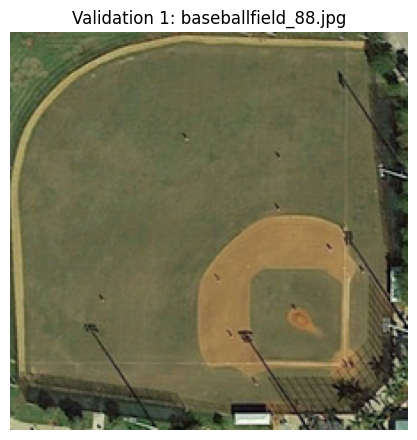

GENERATED: a baseball field is near some green trees.
REFERENCES:
  1. some green trees are around a baseball field .
  2. some green trees are around a baseball field .
  3. some green trees are around a baseball field .
  4. some green trees are around a baseball field .
  5. some green trees are around a baseball field .
------------------------------------------------------------------------------------------


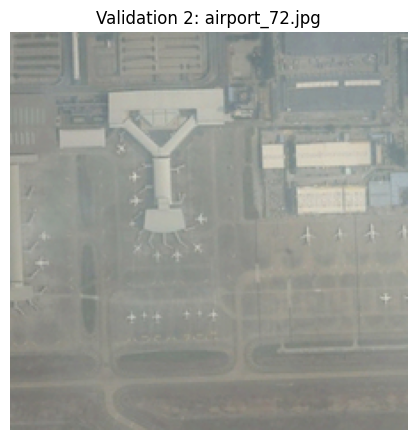

GENERATED: some planes are in an airport near some buildings and green trees.
REFERENCES:
  1. there is a lot of plane parked at the airport .
  2. the airport a lot of white building .
  3. many planes are parked near buildings in an airport .
  4. many planes are parked near buildings in an airport .
  5. there is a lot of plane parked at the airport .
------------------------------------------------------------------------------------------


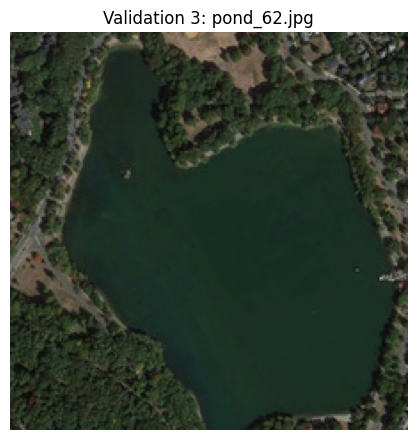

GENERATED: many green trees and some buildings are around a pond.
REFERENCES:
  1. it is a pond with dark green water in the middle .
  2. the pond is surrounded by green plants and houses .
  3. many green trees and some buildings are around an irregular pond .
  4. many green trees and some buildings are around an irregular pond .
  5. it is a pond with dark green water in the middle .
------------------------------------------------------------------------------------------


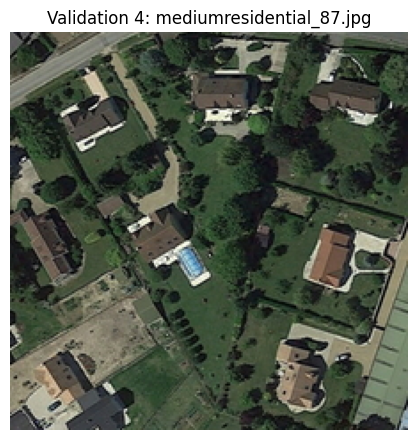

GENERATED: some buildings and green trees are in a medium residential area.
REFERENCES:
  1. many houses surrounded by many green plants in the medium residential .
  2. a medium residential with road beside in it .
  3. some buildings and many green trees are in a medium residential area .
  4. some buildings and many green trees are in a medium residential area .
  5. many houses surrounded by many green plants in the medium residential .
------------------------------------------------------------------------------------------


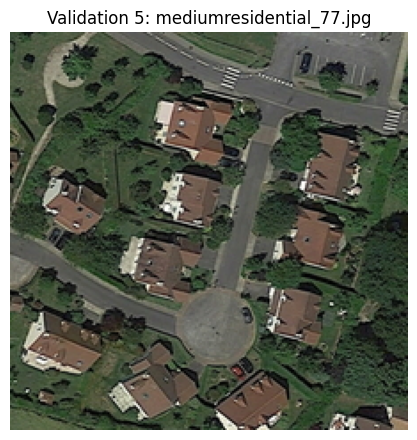

GENERATED: some buildings and green trees are in a medium residential area.
REFERENCES:
  1. many green trees and some buildings are in a medium residential area .
  2. many green trees and some buildings are in a medium residential area .
  3. many green trees and some buildings are in a medium residential area .
  4. many green trees and some buildings are in a medium residential area .
  5. many green trees and some buildings are in a medium residential area .
------------------------------------------------------------------------------------------


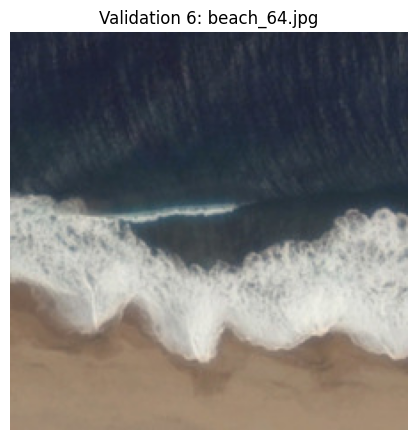

GENERATED: yellow beach is near a piece of green ocean.
REFERENCES:
  1. the water in the sea is very rough .
  2. the scenery is very beautiful on the beach .
  3. white waves in ocean is near a beach .
  4. white waves in ocean is near a beach .
  5. the water in the sea is very rough .
------------------------------------------------------------------------------------------


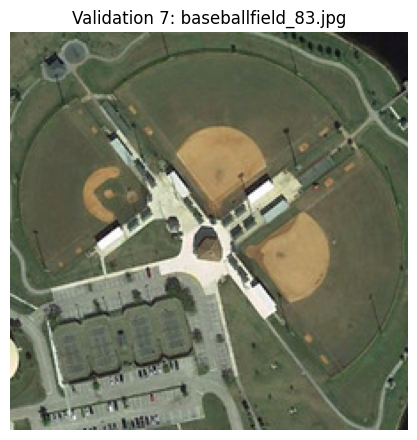

GENERATED: a baseball field is near several green trees.
REFERENCES:
  1. three baseball fields are near a river .
  2. three baseball fields are near a river .
  3. three baseball fields are near a river .
  4. three baseball fields are near a river .
  5. three baseball fields are near a river .
------------------------------------------------------------------------------------------


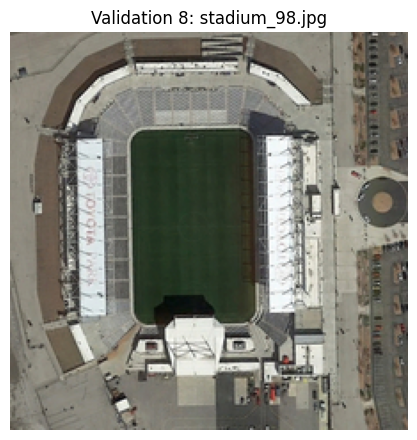

GENERATED: a football field is in the middle of a stadium.
REFERENCES:
  1. the stadium is a wide green lawn .
  2. there are many cars outside the stadium .
  3. a parking lot is near a large stadium .
  4. a parking lot is near a large stadium .
  5. the stadium is a wide green lawn .
------------------------------------------------------------------------------------------


In [18]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

NUM_IMAGES_TO_SHOW = 8
random.seed(42)

val_records = [record for record in dataset_records if record["split"] == "val"]
assert val_records, "No validation records found."
assert IMG_DIR.exists(), f"Image directory not found: {IMG_DIR}"

for index, record in enumerate(random.sample(val_records, min(NUM_IMAGES_TO_SHOW, len(val_records))), start=1):
    image_path = IMG_DIR / record["filename"]
    if not image_path.exists():
        print("Image not found:", image_path)
        continue

    image = Image.open(image_path).convert("RGB")
    prediction = generate_caption(record["raster_ids"])

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(f"Validation {index}: {record['filename']}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    print("GENERATED:", prediction)
    print("REFERENCES:")
    for i, ref in enumerate(record["captions"], start=1):
        print(f"  {i}. {ref}")
    print("-" * 90)

## 16. Install caption-evaluation dependencies

The following cell installs metric packages used below. METEOR may require NLTK WordNet resources; the scoring cell attempts to download the required resource if missing. In restricted environments, package/resource installation may need to be completed before scoring.

In [19]:
%pip install -q nltk rouge-score pycocoevalcap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 18.9 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


## 17. Final test-set scoring

Run this section **only after hyperparameters and checkpoint selection are finalized using validation data**. It generates one caption for each of the 281 held-out test images and compares it with all five references. The cell saves aggregate metrics and `test_prediction.json`, a JSON list with one object per image using the fields `filename`, `scene`, `prediction`, and `references`.

Metrics reported: BLEU-1–4, METEOR, ROUGE-L, and CIDEr. BLEU uses corpus-level whitespace-tokenized captions with smoothing; METEOR is averaged per image; ROUGE-L uses the best reference F-measure per image; CIDEr uses the COCO-style scorer. Because these implementation choices affect scores, keep them fixed when comparing models and document them in reports.

In [20]:
import json
import torch
from pathlib import Path
from tqdm.auto import tqdm
import nltk
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer
from pycocoevalcap.cider.cider import Cider

# METEOR uses WordNet for synonym matching in common NLTK versions.
try:
    nltk.data.find("corpora/wordnet")
except LookupError:
    nltk.download("wordnet", quiet=True)
try:
    nltk.data.find("corpora/omw-1.4")
except LookupError:
    nltk.download("omw-1.4", quiet=True)

OUTPUT_DIR = Path("/kaggle/working/ERIC_Module6b")
SCORE_DIR = OUTPUT_DIR / "test_evaluation"
SCORE_DIR.mkdir(parents=True, exist_ok=True)

# Ensure the selected best checkpoint is loaded for evaluation.
BEST_CHECKPOINT_PATH = OUTPUT_DIR / "checkpoints" / "best_model.pt"
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Detect split and model mismatch before running a costly evaluation.
assert checkpoint["config"]["num_encoder_layers"] == NUM_ENCODER_LAYERS
assert checkpoint["config"]["num_decoder_layers"] == NUM_DECODER_LAYERS

test_records = [record for record in dataset_records if record["split"] == "test"]
assert len(test_records) == 281, f"Expected 281 test images; found {len(test_records)}"

references, hypotheses, prediction_rows = {}, {}, []
for idx, record in enumerate(tqdm(test_records, desc="Generating test captions")):
    image_id = str(idx)
    prediction = generate_caption(record["raster_ids"])
    references[image_id] = record["captions"]
    hypotheses[image_id] = [prediction]
    # The scene is encoded in the RSICD filename (e.g. airport_49.jpg).
    # rsplit removes only the final numeric image suffix, preserving scene names
    # that may themselves contain underscores.
    scene = Path(record["filename"]).stem.rsplit("_", 1)[0]
    prediction_rows.append({
        "filename": record["filename"],
        "scene": scene,
        "prediction": prediction,
        "references": record["captions"],
    })

def words(text):
    return text.lower().strip().split()

bleu_references = [[words(ref) for ref in references[k]] for k in references]
bleu_hypotheses = [words(hypotheses[k][0]) for k in hypotheses]
smooth = SmoothingFunction().method1
bleu_scores = {}
for n in range(1, 5):
    weights = tuple(1.0 / n if i < n else 0.0 for i in range(4))
    bleu_scores[f"BLEU-{n}"] = corpus_bleu(
        bleu_references, bleu_hypotheses, weights=weights,
        smoothing_function=smooth
    )

meteor_values = []
for key in references:
    ref_tokens = [words(ref) for ref in references[key]]
    hyp_tokens = words(hypotheses[key][0])
    meteor_values.append(meteor_score(ref_tokens, hyp_tokens))
meteor = sum(meteor_values) / len(meteor_values)

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
rouge_values = []
for key in references:
    hyp = hypotheses[key][0]
    rouge_values.append(max(
        rouge.score(ref, hyp)["rougeL"].fmeasure for ref in references[key]
    ))
rouge_l = sum(rouge_values) / len(rouge_values)

cider, cider_per_image = Cider().compute_score(references, hypotheses)
results = {
    **{k: float(v) for k, v in bleu_scores.items()},
    "METEOR": float(meteor),
    "ROUGE-L": float(rouge_l),
    "CIDEr": float(cider),
    "test_images": len(test_records),
    "best_checkpoint_epoch": int(checkpoint["epoch"]),
    "best_validation_loss": float(checkpoint["val_loss"]),
    "model_config": checkpoint["config"],
    "metric_protocol": "BLEU corpus-level whitespace tokens with smoothing; METEOR average per image; ROUGE-L max-reference F1 average; COCO-style CIDEr",
}

with open(SCORE_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
PREDICTION_PATH = SCORE_DIR / "test_prediction.json"
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(prediction_rows, f, indent=2, ensure_ascii=False)

print("TEST SET RESULTS")
print("=" * 45)
for metric, value in results.items():
    if isinstance(value, float):
        print(f"{metric:25s}: {value:.4f}")
    elif metric not in {"model_config", "metric_protocol"}:
        print(f"{metric:25s}: {value}")
print("\nMetrics saved to:", SCORE_DIR / "test_metrics.json")
print("Predictions saved to:", PREDICTION_PATH)

Generating test captions:   0%|          | 0/281 [00:00<?, ?it/s]

TEST SET RESULTS
BLEU-1                   : 0.5175
BLEU-2                   : 0.3719
BLEU-3                   : 0.2877
BLEU-4                   : 0.2357
METEOR                   : 0.3487
ROUGE-L                  : 0.4309
CIDEr                    : 0.3354
test_images              : 281
best_checkpoint_epoch    : 3
best_validation_loss     : 1.8168

Metrics saved to: /kaggle/working/ERIC_Module6b/test_evaluation/test_metrics.json
Predictions saved to: /kaggle/working/ERIC_Module6b/test_evaluation/test_prediction.json


## 18. Interpretation and limitations

When reporting results, include the selected checkpoint epoch and validation loss, the full metric protocol, and examples of generated captions. Do not compare scores from different tokenization or reference-handling protocols as if they were directly equivalent.

Known limitations:

1. **Pseudo-label quality:** incorrect cell labels constrain the caption generator.
2. **Spatial coarseness:** a 7×7 grid loses fine-grained details and object relations.
3. **Scene bias:** the raster may strongly encode scene identity (e.g., airport) while omitting image-specific attributes.
4. **Reference duplication:** many images have duplicate captions; this is retained to preserve the source annotations.
5. **Raster-only scope:** no original image features are used in this module, so results are not directly comparable to image-input captioning baselines without a clear protocol.
6. **Edge claims:** this module alone does not measure end-to-end raster-generation latency, energy, or transmission cost. Those require separate profiling.